## Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

### 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


**Regler le prbl des individus présent uniquement dans certaines tables :**  
On a 5855 individus dans `description-indiv.csv` initiallement, mais uniquement 4013 individus commun à toutes les tables. On en conserve donc une grosse parti et on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [17]:
d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False) #, low_memory=False uniquement pour supprimer le warning sur les colonnes de type object (colonnes qu'on supprime après de tte manière)
d_gpe = pd.read_csv("tables/conso-gpe-inca3.csv", sep=";")
d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")
d_hab = pd.read_csv("tables/habitudes-indiv.csv", sep=";", low_memory=False)

noind_communs = set(d_gpe['NOIND']) & set(d_app['NOIND']) & set(d_hab['NOIND']) & set(d_descri['NOIND'])

print(f"Nombre d'individus dans description-indiv.csv : {len(d_descri)}")
print(f"Nombre d'individus dans conso-gpe-inca3.csv : {len(d_gpe)}")
print(f"Nombre d'individus dans apports-nut-alim.csv : {len(d_app)}")
print(f"Nombre d'individus dans habitudes-indiv.csv : {len(d_hab)}")
print(f"Nombre total d'individus communs : {len(noind_communs)}")

df = (
    d_descri[d_descri["NOIND"].isin(noind_communs)]
    # .merge(
    #     d_gpe[d_gpe["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("_descri", "_gpe")
    # )
    # .merge(
    #     d_app[d_app["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("", "_app")
    # )
    # .merge(
    #     d_hab[d_hab["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("", "_hab")
    # )
)

Nombre d'individus dans description-indiv.csv : 5855
Nombre d'individus dans conso-gpe-inca3.csv : 4114
Nombre d'individus dans apports-nut-alim.csv : 4114
Nombre d'individus dans habitudes-indiv.csv : 4372
Nombre total d'individus communs : 4013


**Regler le prbl des colonnes str :**  
On a 8 colonnes str :
- `zae` : on supprime juste le Z d'entete et ca devient un int c'est good
- les colonnes finissant par `*_libelle` ne contiennent que peut d'information, et c'est des choses rentrées à la main par les personnes $\to$ on ne se prend pas la tête pour une étude large et on en tiens pas compte = suppression

In [18]:
nb_str = len(df.select_dtypes(include=['object', 'string']).columns)
nb_num = len(df.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = df.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    # print(d_str[k].unique())

df["zae"] = df["zae"].str[1:].astype("Int64") # Z78267 -> 78267
colonnes_libelle = df.columns[df.columns.str.endswith("_libelle")]
df.drop(columns=colonnes_libelle, inplace=True) # supprimer les colonnes *_libelles, les raisons du oui à la colonne d'avant, annecdotique pour nous

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 8
Nombre de colonnes au format numérique (int/float) : 177


Colonne 'zae' : 181 valeurs uniques, 0 valeurs manquantes
Colonne 'regime_raisonmed_libelle' : 101 valeurs uniques, 3853 valeurs manquantes
Colonne 'veget_autre_alim_libelle' : 1 valeurs uniques, 4012 valeurs manquantes
Colonne 'allergie_fruitcoque_libelle' : 12 valeurs uniques, 3997 valeurs manquantes
Colonne 'allergie_autres_fl_libelle' : 27 valeurs uniques, 3979 valeurs manquantes
Colonne 'allergie_autresalim_libelle' : 15 valeurs uniques, 1956 valeurs manquantes
Colonne 'regime_type_libelle' : 23 valeurs uniques, 3936 valeurs manquantes
Colonne 'poids_modifalim_autre_libelle' : 21 valeurs uniques, 3956 valeurs manquantes


**Affichage graphique des valeurs manquantes avant et après nettoyage des colonnes str**

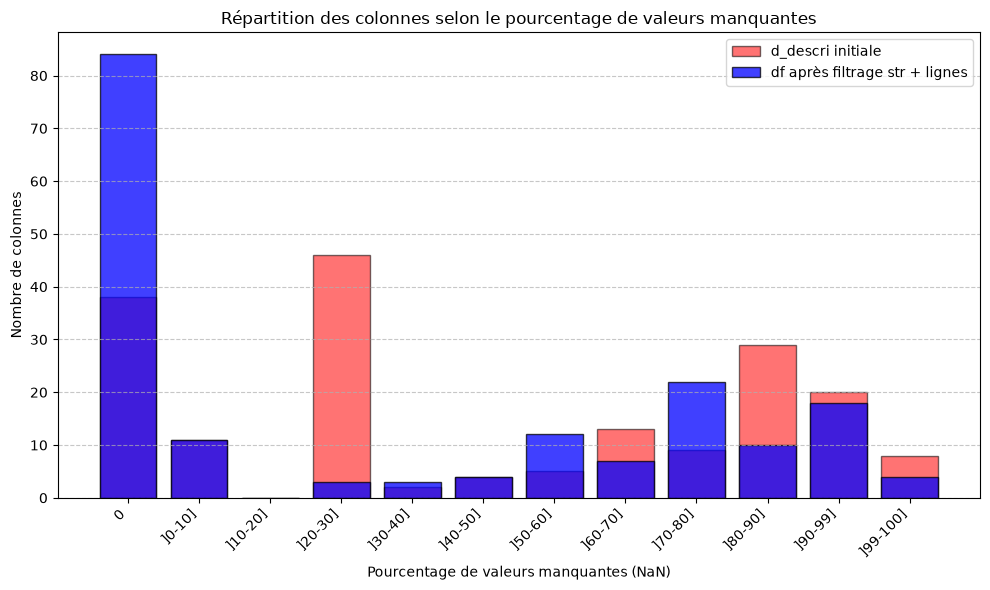

In [19]:
# Pourcentage de valeurs manquantes dans les deux tables
nan_descri = d_descri.isna().mean() * 100
nan_df = df.isna().mean() * 100

bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    '0', ']0-10]', ']10-20]', ']20-30]', ']30-40]', ']40-50]',
    ']50-60]', ']60-70]', ']70-80]', ']80-90]', ']90-99]', ']99-100]'
]

counts_descri = pd.cut(
    nan_descri, bins=bins, labels=labels
).value_counts(sort=False)

counts_df = pd.cut(
    nan_df, bins=bins, labels=labels
).value_counts(sort=False)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))

# Table d_descri en arrière-plan
plt.bar(
    x, counts_descri.values,
    color='red', alpha=0.55,
    edgecolor='black', label='d_descri initiale'
)

# Table df au premier plan
plt.bar(
    x, counts_df.values,
    color='blue', alpha=0.75,
    edgecolor='black', label='df après filtrage str + lignes'
)

plt.title("Répartition des colonnes selon le pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes (NaN)")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# plt.savefig("graphs/nan_distribution_comparaison.png")
plt.show()

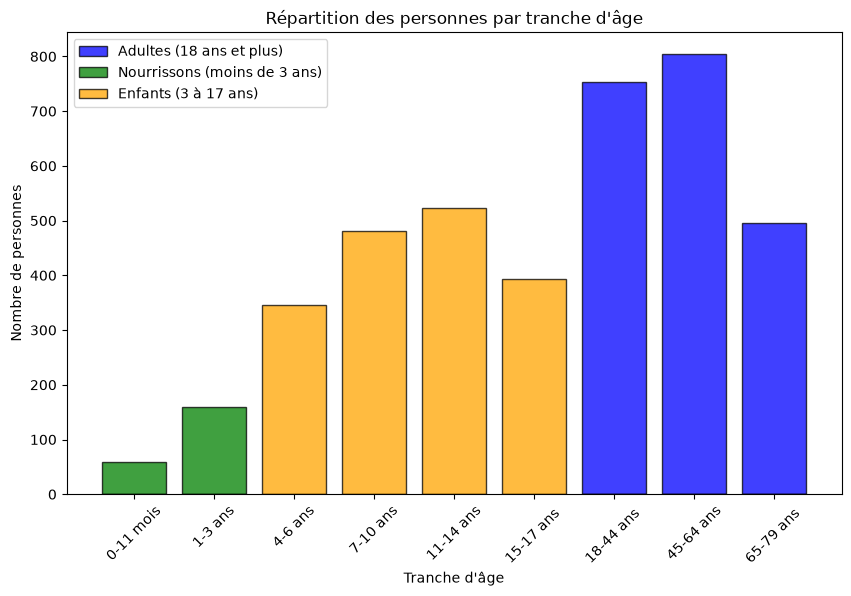

In [20]:
df_adulte = df[df["tage_PS"] >= 7]
df_nourisson = df[df["tage_PS"] < 3]
df_enfant = df[(df["tage_PS"] >= 3) & (df["tage_PS"] < 7)]

bins = [0,1,2,3,4,5,6,7,8,9]
labels = ['0-11 mois', '1-3 ans', '4-6 ans', '7-10 ans', '11-14 ans', '15-17 ans ', '18-44 ans ', '45-64 ans', '65-79 ans ']

counts_adulte = pd.cut(df_adulte["tage_PS"], bins=bins, labels=labels)
counts_nourisson = pd.cut(df_nourisson["tage_PS"], bins=bins, labels=labels)
counts_enfant = pd.cut(df_enfant["tage_PS"], bins=bins, labels=labels)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))
plt.bar(x, counts_adulte.value_counts(sort=False), color='blue', alpha=0.75, edgecolor='black', label='Adultes (18 ans et plus)')
plt.bar(x, counts_nourisson.value_counts(sort=False), color='green', alpha=0.75, edgecolor='black', label='Nourrissons (moins de 3 ans)')
plt.bar(x, counts_enfant.value_counts(sort=False), color='orange', alpha=0.75, edgecolor='black', label='Enfants (3 à 17 ans)')
plt.xlabel('Tranche d\'âge')
plt.ylabel('Nombre de personnes')
plt.title('Répartition des personnes par tranche d\'âge')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()


**Regler le problèmes des valeurs manquantes :**  
- Colonnes vides = suppression
- très peu de valeurs manquantes (<1% par exemple) = suppresion ligne
- bcp valeur manquantes : verification si c'est pas juste un 0 non encodé, ou resoudre le prbl. Si pas possible = ecarter la colonne
- Valeurs manquantes = "Non applicable" : la valeur manquante ne signifie pas un oublie ou un non, par exemple si on a repondu être un homme, il est logique qu'il n'y ai rien dans enceinte, répondre "non" est une information innatendue. Il faut imputer "non applicable"

--- Adultes ---
Adultes : 7 colonne(s) vide supprimée(s)
Colonne 'diplome_interv' : 12 valeurs uniques, 0.05% de valeurs manquantes
Colonne 'atrav_interv' : 2 valeurs uniques, 53.77% de valeurs manquantes
Colonne 'trav_nuit_interv' : 4 valeurs uniques, 46.23% de valeurs manquantes
Colonne 'trav_nuit_2cl_interv' : 2 valeurs uniques, 46.23% de valeurs manquantes
Colonne 'tps_travail_interv' : 2 valeurs uniques, 3.75% de valeurs manquantes
Colonne 'lien_interv_PR' : 4 valeurs uniques, 65.32% de valeurs manquantes
Colonne 'lien_PS_PR' : 4 valeurs uniques, 65.32% de valeurs manquantes
Colonne 'diplome_PR' : 14 valeurs uniques, 0.10% de valeurs manquantes
Colonne 'atrav_PR' : 3 valeurs uniques, 55.92% de valeurs manquantes
Colonne 'tps_travail_PR' : 2 valeurs uniques, 1.61% de valeurs manquantes
Colonne 'RUC_4cl' : 4 valeurs uniques, 7.65% de valeurs manquantes
Colonne 'IA_score' : 6 valeurs uniques, 86.60% de valeurs manquantes
Colonne 'taille_m' : 51 valeurs uniques, 4.38% de valeurs manqu

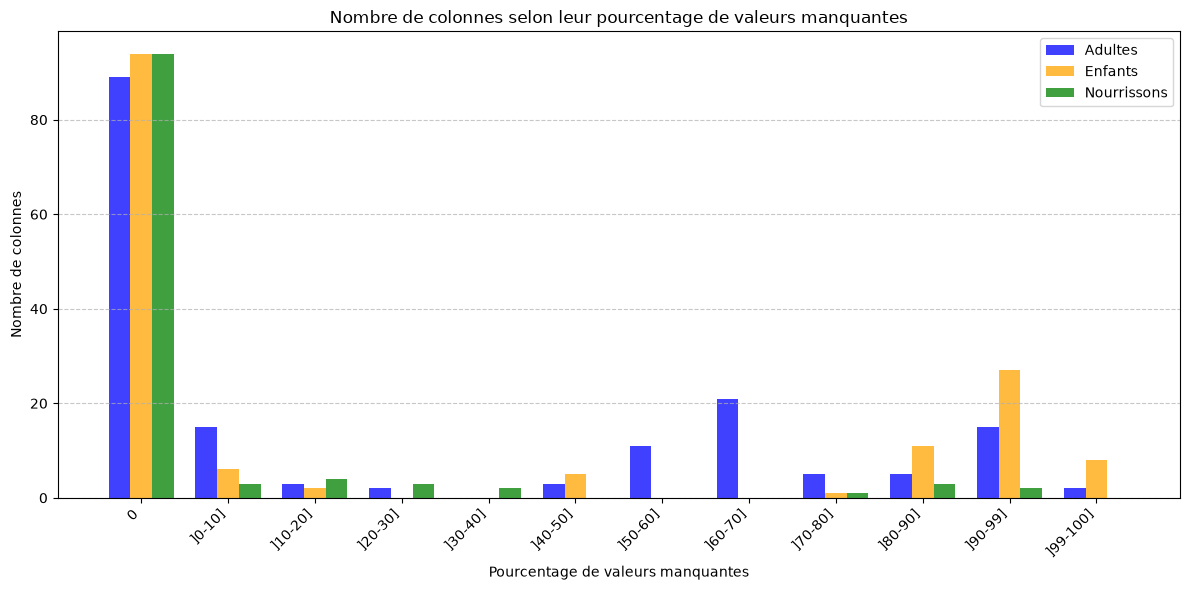

In [21]:
dfs = {
    "Adultes": df_adulte,
    "Enfants": df_enfant,
    "Nourrissons": df_nourisson
}

for nom, data in dfs.items():
    # 1. Supprimer les colonnes vides
    colonnes_vides = data.columns[data.isna().all()]
    data.drop(columns=colonnes_vides, inplace=True)

    # 2. Afficher les informations sur les colonnes restantes
    print(f"--- {nom} ---")
    print(f"{nom} : {len(colonnes_vides)} colonne(s) vide supprimée(s)")
    for k in data.columns:
        if data[k].isna().sum() > 0:
            print(
                f"Colonne '{k}' : "
                f"{data[k].nunique()} valeurs uniques, "
                f"{data[k].isna().sum()/len(data)*100:.2f}% de valeurs manquantes"
            )
    print('\n')



# Pourcentage de valeurs manquantes par colonne
bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    "0", "]0-10]", "]10-20]", "]20-30]", "]30-40]", "]40-50]",
    "]50-60]", "]60-70]", "]70-80]", "]80-90]", "]90-99]", "]99-100]"
]

comptages = {}

for nom, data in dfs.items():
    pourcentage_nan = data.isna().mean() * 100
    classes_nan = pd.cut(
        pourcentage_nan,
        bins=bins,
        labels=labels,
        include_lowest=True
    )
    comptages[nom] = classes_nan.value_counts(sort=False)

x = np.arange(len(labels))
largeur = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - largeur, comptages["Adultes"],
    width=largeur, color="blue", alpha=0.75, label="Adultes"
)
plt.bar(
    x, comptages["Enfants"],
    width=largeur, color="orange", alpha=0.75, label="Enfants"
)
plt.bar(
    x + largeur, comptages["Nourrissons"],
    width=largeur, color="green", alpha=0.75, label="Nourrissons"
)

plt.title("Nombre de colonnes selon leur pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

### Comment coder « non applicable » dans une colonne numérique

On ne peut pas mettre une chaîne de caractères dans une colonne `int`/`float` : elle passerait en `object` et on perdrait moyennes, régressions, histogrammes... La solution est une **valeur sentinelle numérique** : `NA_APPL = -1`.
- aucune colonne du jeu de données ne contient de valeur négative $\to$ aucune confusion possible avec une vraie réponse (0 reste « Non » / « aucun »)
- `NaN` ne veut plus dire que **« vraie valeur manquante »**, c'est exactement ce qu'on imputera plus tard (moyenne / régression)
- le masque des cases non applicables s'obtient quand on veut avec `df.eq(NA_APPL)`

Pour choisir entre les trois cas :

|situation|exemple|on met|
|---|---|---|
|la réponse est logiquement certaine|femme ménopausée $\to$ pas enceinte ; jamais fumé $\to$ 0 cigarette|la valeur déduite (0, Non...)|
|la question n'a pas de sens ou n'a pas été posée|homme $\to$ grossesse ; enfant de 6 ans $\to$ tabac|`NA_APPL`|
|la question était applicable mais pas de réponse|adulte qui ne donne pas son poids maximum|on laisse `NaN`|

⚠️ Avant une moyenne, une régression ou un `describe()`, il faut repasser les `-1` en `NaN` avec `sans_non_applicable(df)`, sinon ils faussent les calculs.

In [22]:
NA_APPL = -1  # code "non applicable"

num = df.select_dtypes(include="number")
assert not (num < 0).any().any(), "Il y a déjà des valeurs négatives : choisir un autre code"

def remplir(data, masque, colonnes, valeur):
    '''Écrit `valeur` dans `colonnes` pour les lignes de `masque`, UNIQUEMENT là où la case est vide (NaN).
    On n'écrase donc jamais une vraie réponse.'''
    colonnes = [colonnes] if isinstance(colonnes, str) else list(colonnes)
    for col in colonnes:
        data.loc[masque & data[col].isna(), col] = valeur

def connue(serie):
    '''Vrai là où on a une vraie valeur (ni NaN, ni non applicable)'''
    return serie.notna() & serie.ne(NA_APPL)

def sans_non_applicable(data):
    '''Copie avec NaN à la place de NA_APPL : à utiliser pour moyennes, régressions, imputations'''
    return data.mask(data.eq(NA_APPL))

def bilan_na(avant, apres):
    '''Tableau NaN avant / après / non applicable, colonne par colonne'''
    t = pd.DataFrame({
        "NaN_avant": avant.isna().sum(),
        "NaN_apres": apres.isna().sum(),
        "non_applicable": apres.eq(NA_APPL).sum(),
    })
    t["NaN_restants_%"] = (100 * t["NaN_apres"] / len(apres)).round(1)
    return t

### Colonnes ou on remplace nan par 0 :
1. Le tabagisme : six quantités  

|format_fume|signification|  
|---|---|  
|1|Oui, quotidiennement|  
|2|Oui, occasionnellement|  
|3|Non, mais a déjà fumé|  
|4|Non, jamais fumé|  

- donc si `fume` vaut 3 ou 4, on peut logiquement mettre 0 dans `nb_cigarettes_jour`, `nb_cigarettes_sem`, `nb_cigarettes_nsp `, `nb_cigares_jour`, `nb_cigares_sem`,  `nb_cigares_nsp`, `nb_pipes_jour`, `nb_pipes_sem`, `nb_pipes_nsp`
- Si `fume` vaut 4, on peut mettre $non applicable$ dans `fume_age_debut`, `ume_age_debut_nsp`, `fume_age_arret`, `fume_age_arret_nsp`
- Si `fume` vaut 1 ou 2, et qu'on a :
  - si `nb_*_nsp` == 1, on met $NaN$ ou 200 dans les 6 autres catégories (`*_jour` et `*_sem`)
  - si `nb_*_jour` == nan et `nb_*_sem` == x, on peut `nb_*_jour` = x / 7 (on aura pas des entier)
  - si `nb_*_sem` == nan et `nb_*_jour` == x, on peut `nb_*_sem` = x * 7 (on aura pas des entier)
  - si on a un chiffre dans cigarette, cigares ou pipe mais pas les autres, on met 0 dans les autres catégories

In [23]:
colonnes_fume = ["NOIND", "fume", "nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp", "nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp", "nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp", "fume_age_debut", "fume_age_debut_nsp", "fume_age_arret", "fume_age_arret_nsp"]

d_fume = df.loc[:, colonnes_fume].copy()

colonnes_nb = [col for col in d_fume.columns if col.startswith("nb_")]
colonnes_age = [col for col in d_fume.columns if col.startswith("fume_age_")]

# AJOUT : la question tabac n'est posée qu'à partir de 11 ans (tage_PS >= 5) -> non applicable en dessous
remplir(d_fume, df["tage_PS"] < 5, [c for c in colonnes_fume if c != "NOIND"], NA_APPL)

''' Pour trouver 2 individus qui posaient problèmes
autres_colonnes_fume = [col for col in colonnes_fume if col != "NOIND"]

masque = (
    df["fume"].isna()
    & df[autres_colonnes_fume].notna().any(axis=1)
)

print(df.loc[masque, colonnes_fume])

'''

# AJOUT : les 2 individus dont `fume` est vide mais qui ont des infos de consommation et pas d'âge d'arrêt
# = fumeurs actuels ; quotidien si une quantité/jour est renseignée, sinon occasionnel
conso_jour = d_fume[["nb_cigarettes_jour", "nb_cigares_jour", "nb_pipes_jour"]].fillna(0).gt(0).any(axis=1)
conso_sem = d_fume[["nb_cigarettes_sem", "nb_cigares_sem", "nb_pipes_sem"]].fillna(0).gt(0).any(axis=1)
pas_arret = d_fume[["fume_age_arret", "fume_age_arret_nsp"]].isna().all(axis=1)
d_fume.loc[d_fume["fume"].isna() & conso_jour & pas_arret, "fume"] = 1
d_fume.loc[d_fume["fume"].isna() & conso_sem & pas_arret, "fume"] = 2

idx = {
    k: d_fume.index[d_fume["fume"].eq(k)].to_numpy()
    for k in range(1, 5)
}

groupes = {
    "cigarettes": ["nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp"],
    "cigares": ["nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp"],
    "pipes": ["nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp"],
}

# Si a déjà fumé (fume = 3) : consommation actuelle = 0
# (ça écrase les quantités déclarées pour la période où la personne fumait)
indices = idx[3]
d_fume.loc[indices, colonnes_nb] = 0

# Si n'a jamais fumé (fume = 4) : quantités = 0, âges = non applicable
indices = idx[4]
d_fume.loc[indices, colonnes_nb] = 0
d_fume.loc[indices, colonnes_age] = NA_APPL

# MODIF : le bloc "fume = 2" qui mettait toutes les quantités à 0 est supprimé :
# fume = 2 = fumeur OCCASIONNEL (58 d'entre eux ont une quantité/semaine), il écrasait de vraies réponses

# AJOUT : fumeur actuel (1 ou 2) -> n'a pas arrêté -> âge d'arrêt non applicable
remplir(d_fume, d_fume["fume"].isin([1, 2]), ["fume_age_arret", "fume_age_arret_nsp"], NA_APPL)

# Si fume actuellement (fume = 1 ou 2)
for groupe, colonnes in groupes.items():
    jour, sem, nsp = colonnes

    # Si la quantité est non spécifiée, les quantités jour et semaine
    # ne peuvent pas être déterminées
    mask_nsp = d_fume["fume"].isin([1, 2]) & d_fume[nsp].eq(1)
    d_fume.loc[mask_nsp, [jour, sem]] = np.nan

    # Conversion entre quantités journalières et hebdomadaires
    mask_jour = (
        d_fume["fume"].isin([1, 2])
        & d_fume[jour].isna()
        & d_fume[sem].notna()
        & d_fume[nsp].ne(1)
    )
    d_fume.loc[mask_jour, jour] = d_fume.loc[mask_jour, sem] / 7

    mask_sem = (
        d_fume["fume"].isin([1, 2])
        & d_fume[sem].isna()
        & d_fume[jour].notna()
        & d_fume[nsp].ne(1)
    )
    d_fume.loc[mask_sem, sem] = d_fume.loc[mask_sem, jour] * 7

# Si une catégorie de tabac est consommée, les autres catégories
# sont mises à 0 uniquement si leurs quantités sont toutes manquantes
for groupe_source, colonnes_source in groupes.items():
    masque_source = (
        d_fume["fume"].isin([1, 2])
        & d_fume[colonnes_source[:2]].fillna(0).gt(0).any(axis=1)
    )

    for groupe_cible, colonnes_cible in groupes.items():
        if groupe_cible == groupe_source:
            continue

        masque_cible = d_fume[colonnes_cible].isna().all(axis=1)
        masque = masque_source & masque_cible
        d_fume.loc[masque, colonnes_cible] = 0

# AJOUT : "ne sait pas" = 0 quand la valeur est connue (sinon NaN ne voudrait plus rien dire)
for jour, sem, nsp in groupes.values():
    remplir(d_fume, d_fume["fume"].isin([1, 2, 3]) & (connue(d_fume[jour]) | connue(d_fume[sem])), nsp, 0)
remplir(d_fume, connue(d_fume["fume_age_debut"]), "fume_age_debut_nsp", 0)
remplir(d_fume, connue(d_fume["fume_age_arret"]), "fume_age_arret_nsp", 0)

comparaison_na = pd.DataFrame({
    "NaN_avant_df": df[colonnes_fume].isna().sum(),
    "NaN_apres_d_fume": d_fume[colonnes_fume].isna().sum(),
    "non_applicable": d_fume[colonnes_fume].eq(NA_APPL).sum()
})

comparaison_na["difference_NaN"] = (
    comparaison_na["NaN_apres_d_fume"] - comparaison_na["NaN_avant_df"]
)

comparaison_na

,NaN_avant_df,NaN_apres_d_fume,non_applicable,difference_NaN
NOIND,0,0,0,0
fume,1079,33,1044,-1046
nb_cigarettes_jour,3098,58,1044,-3040
nb_cigarettes_sem,3874,58,1044,-3816
nb_cigarettes_nsp,3931,35,1044,-3896
nb_cigares_jour,3049,66,1044,-2983
nb_cigares_sem,3918,66,1044,-3852
nb_cigares_nsp,3939,35,1044,-3904
nb_pipes_jour,3075,67,1044,-3008
nb_pipes_sem,3930,67,1044,-3863


2. Historique des régimes amaigrissants

|regime_passe|signification|  
|---|---|  
|1|Oui|  
|2|Non|  
|3|Ne sait pas|  
|4|Refus|  

- si `regime_passe` == 2, on peut mettre 0/$non-applicable$ dans `regime_nb_2dernann`, `regime_nb_anter2dernann `, `regime_nb_anter2dernann  `, `regime_duree_sem`, `regime_duree_mois`, `regime_duree_nsp`
- transformer toutes les `regime_duree_mois` en `regime_duree_sem`, ou faire *4 /4 pour remplir les cases vides si possible

In [24]:
colonnes_regime = ["regime_passe", "regime_nb_2dernann", "regime_nb_anter2dernann", "regime_type",
                   "regime_duree_sem", "regime_duree_mois", "regime_duree_nsp"]
nb_reg = ["regime_nb_2dernann", "regime_nb_anter2dernann"]
duree = ["regime_duree_sem", "regime_duree_mois", "regime_duree_nsp"]

d_reg = df.loc[:, colonnes_regime].copy()

# le code 7 n'existe pas dans la notice (format_regime_nb : 1 à 6) et va avec un regime_type vide -> manquant
d_reg[nb_reg] = d_reg[nb_reg].replace(7, np.nan)

# regime_passe n'est posée qu'à partir de 15 ans (tage_PS >= 6) -> non applicable en dessous
remplir(d_reg, df["tage_PS"] < 6, colonnes_regime, NA_APPL)

# Jamais fait de régime (regime_passe = 2) : 0 régime ; type et durée n'ont pas de sens
non = d_reg["regime_passe"].eq(2)
remplir(d_reg, non, nb_reg, 0)
remplir(d_reg, non, ["regime_type"] + duree, NA_APPL)

# Durée : la personne donne soit des semaines, soit des mois -> on remplit l'autre colonne
SEM_PAR_MOIS = 52 / 12  # mettre 4 pour la règle "*4 /4"
oui = d_reg["regime_passe"].eq(1)

mask_sem = oui & d_reg["regime_duree_sem"].isna() & d_reg["regime_duree_mois"].notna()
d_reg.loc[mask_sem, "regime_duree_sem"] = d_reg.loc[mask_sem, "regime_duree_mois"] * SEM_PAR_MOIS

mask_mois = oui & d_reg["regime_duree_mois"].isna() & d_reg["regime_duree_sem"].notna()
d_reg.loc[mask_mois, "regime_duree_mois"] = d_reg.loc[mask_mois, "regime_duree_sem"] / SEM_PAR_MOIS

# "ne sait pas la durée" = 0 quand la durée est connue
remplir(d_reg, oui & connue(d_reg["regime_duree_sem"]), "regime_duree_nsp", 0)

bilan_na(df[colonnes_regime], d_reg)

,NaN_avant,NaN_apres,non_applicable,NaN_restants_%
regime_passe,1593,26,1567,0.6
regime_nb_2dernann,3351,131,1567,3.3
regime_nb_anter2dernann,3393,193,1567,4.8
regime_type,3409,126,3283,3.1
regime_duree_sem,3924,270,3283,6.7
regime_duree_mois,3642,270,3283,6.7
regime_duree_nsp,3868,125,3283,3.1


3. Poids : tentatives de changement, poids passé, poids max / min

- les questions ne sont pas posées à tous les âges : `poids_modif` et `poids_perception` dès 11 ans (`tage_PS` $\geq$ 5), `poids_anndern` dès 15 ans ($\geq$ 6), `poidsmax`, `poidsmin`, leurs âges et `nb_prise_10kg` pour les adultes seulement ($\geq$ 7) $\to$ $non\ applicable$ en dessous
- `poids_modif` = 3 (a voulu grossir) ou 4 (ne s'est pas préoccupé de son poids) : il n'a forcément pas essayé de perdre / ne pas prendre de poids par l'alimentation, les médicaments... $\to$ 0 dans les 5 colonnes de moyens. Avec 5 (ne sait pas) on ne peut rien déduire, on laisse `NaN`
- `poids_modifalim_*` (quantités modifiées pour chaque aliment) n'est posée que si `poids_modifalim` = 1 $\to$ $non\ applicable$ si `poids_modifalim` = 0
- `*_nsp` = 0 quand la valeur est connue

In [25]:
moyens = ["poids_modifalim", "poids_plusAP", "poids_medicaments", "poids_substituts", "poids_chirurgie"]
qtes = [c for c in df.columns if c.startswith("poids_modifalim_") and not c.endswith("_libelle")]
adulte_seul = ["poidsmax", "poidsmax_nsp", "age_poidsmax", "age_poidsmax_nsp",
               "poidsmin", "poidsmin_nsp", "age_poidsmin", "age_poidsmin_nsp", "nb_prise_10kg"]
colonnes_poids = (["poids_anndern", "poids_anndern_nsp", "poids_modif", "poids_perception"]
                  + moyens + qtes + adulte_seul)

d_poids = df.loc[:, colonnes_poids].copy()
age = df["tage_PS"]

# Questions non posées selon l'âge
remplir(d_poids, age < 5, ["poids_modif", "poids_perception"] + moyens + qtes, NA_APPL)
remplir(d_poids, age < 6, ["poids_anndern", "poids_anndern_nsp"], NA_APPL)
remplir(d_poids, age < 7, adulte_seul, NA_APPL)

# N'a pas essayé de perdre / ne pas prendre de poids -> "Non" pour chaque moyen
remplir(d_poids, d_poids["poids_modif"].isin([3, 4]), moyens, 0)

# Quantités modifiées : seulement si a modifié son alimentation
remplir(d_poids, d_poids["poids_modifalim"].eq(0), qtes, NA_APPL)

# "ne sait pas" = 0 quand la valeur est connue
for val in ["poids_anndern", "poidsmax", "age_poidsmax", "poidsmin", "age_poidsmin"]:
    remplir(d_poids, connue(d_poids[val]), val + "_nsp", 0)

bilan_na(df[colonnes_poids], d_poids)

,NaN_avant,NaN_apres,non_applicable,NaN_restants_%
poids_anndern,2019,452,1567,11.3
poids_anndern_nsp,3634,73,1567,1.8
poids_modif,1100,56,1044,1.4
poids_perception,1069,25,1044,0.6
poids_modifalim,2786,159,1044,4.0
poids_plusAP,2790,163,1044,4.1
poids_medicaments,2790,163,1044,4.1
poids_substituts,2790,163,1044,4.1
poids_chirurgie,2790,163,1044,4.1
poids_modifalim_laityaourt,3135,269,2866,6.7


4. Ménopause, grossesse, allaitement

- hommes $\to$ $non\ applicable$ partout (une grossesse n'a pas de sens, répondre « non » serait une information inattendue)
- `menopause` n'est posée qu'aux femmes de 18 ans et plus ($\geq$ 7), les autres questions dès 15 ans ($\geq$ 6) $\to$ $non\ applicable$ en dessous
- femme ménopausée : la réponse est certaine, elle n'est pas enceinte (`enceinte` = 2), n'allaite pas et n'a pas été enceinte dans l'année (0), c'est bien un « non » et pas un « non applicable »
- `enceinte_nbmois` = 0 si `enceinte` = 2, `allaite_nbsem` = 0 si `allaite` = 0

In [26]:
colonnes_femmes = ["menopause", "enceinte", "enceinte_nbmois", "allaite", "allaite_nbsem", "enceinte_12dermois"]
d_fem = df.loc[:, colonnes_femmes].copy()

remplir(d_fem, df["sex_PS"].eq(1), colonnes_femmes, NA_APPL)          # hommes
remplir(d_fem, df["tage_PS"] < 7, "menopause", NA_APPL)               # ménopause : 18 ans et +
remplir(d_fem, df["tage_PS"] < 6, colonnes_femmes[1:], NA_APPL)       # grossesse / allaitement : 15 ans et +

# Femme ménopausée : certain que non
menopausee = d_fem["menopause"].eq(1)
remplir(d_fem, menopausee, "enceinte", 2)                              # 2 = Non (format_ouinonnsp)
remplir(d_fem, menopausee, ["allaite", "enceinte_12dermois"], 0)      # 0 = Non (format_ouinon)

# Quantités : 0 si pas enceinte / n'allaite pas
remplir(d_fem, d_fem["enceinte"].eq(2), "enceinte_nbmois", 0)
remplir(d_fem, d_fem["allaite"].eq(0), "allaite_nbsem", 0)

bilan_na(df[colonnes_femmes], d_fem)

,NaN_avant,NaN_apres,non_applicable,NaN_restants_%
menopause,2836,15,2821,0.4
enceinte,3238,21,2621,0.5
enceinte_nbmois,3998,28,2621,0.7
allaite,3239,22,2621,0.5
allaite_nbsem,4012,37,2621,0.9
enceinte_12dermois,3241,24,2621,0.6


5. Situation professionnelle et lien avec la personne de référence (PR)

- `atrav_interv` (« a déjà exercé une profession ») n'est posée qu'aux personnes sans emploi : si `situ_prof_5cl_interv` = 1 (occupe un emploi) la réponse est forcément Oui. Pareil pour `atrav_PR` avec `PCS_8cl_PR` de 1 à 6 (actifs)
- `trav_nuit_interv` et `trav_nuit_2cl_interv` ne sont posées qu'à ceux qui ont un emploi $\to$ $non\ applicable$ sinon
- `tps_travail_*` (temps plein / partiel) n'est posée qu'à ceux qui ont déjà travaillé $\to$ $non\ applicable$ si `atrav_*` = 2
- `lien_interv_PR` : si l'interviewé est la PR (`interv_PR` = 1), le lien avec lui-même n'a pas de sens $\to$ $non\ applicable$. Idem pour `lien_PS_PR` quand la PS est un adulte
- `lien_PS_PR` pour un enfant dont le parent interviewé est la PR : c'est son enfant (code 2 « Enfant »)

In [27]:
colonnes_pro = ["atrav_interv", "trav_nuit_interv", "trav_nuit_2cl_interv", "tps_travail_interv",
                "atrav_PR", "tps_travail_PR", "lien_interv_PR", "lien_PS_PR"]
d_pro = df.loc[:, colonnes_pro].copy()

# Interviewé
a_un_emploi = df["situ_prof_5cl_interv"].eq(1)
remplir(d_pro, a_un_emploi, "atrav_interv", 1)                                      # 1 = Oui
remplir(d_pro, ~a_un_emploi, ["trav_nuit_interv", "trav_nuit_2cl_interv"], NA_APPL)
remplir(d_pro, d_pro["atrav_interv"].eq(2), "tps_travail_interv", NA_APPL)

# Personne de référence
remplir(d_pro, df["PCS_8cl_PR"].between(1, 6), "atrav_PR", 1)
remplir(d_pro, d_pro["atrav_PR"].eq(2), "tps_travail_PR", NA_APPL)

# Liens
interv_est_PR = df["interv_PR"].eq(1)
adulte = df["tage_PS"] >= 7
remplir(d_pro, interv_est_PR, "lien_interv_PR", NA_APPL)
remplir(d_pro, interv_est_PR & adulte, "lien_PS_PR", NA_APPL)
remplir(d_pro, interv_est_PR & ~adulte & df["lien_rep_enf"].isin([1, 2]), "lien_PS_PR", 2)  # 2 = Enfant

bilan_na(df[colonnes_pro], d_pro)

,NaN_avant,NaN_apres,non_applicable,NaN_restants_%
atrav_interv,2734,0,0,0.0
trav_nuit_interv,1279,0,1279,0.0
trav_nuit_2cl_interv,1279,0,1279,0.0
tps_travail_interv,113,0,113,0.0
atrav_PR,2912,1,0,0.0
tps_travail_PR,44,2,42,0.0
lien_interv_PR,2191,0,2191,0.0
lien_PS_PR,2191,7,1341,0.2


6. Autres colonnes

- `intoall_confirm_med` (allergie confirmée par un médecin) n'est posée que si `maladie_allergie_alim` = 1 $\to$ $non\ applicable$ sinon
- `regime_forme` n'est pas posée aux 0-35 mois (`tage_PS_mois` renseigné) $\to$ $non\ applicable$
- `IA_score` n'existe pas quand `IA_statut` = 0 (pas d'insécurité alimentaire, pas de score calculé) $\to$ $non\ applicable$
- `taille` et `poids` sont déjà complets : `taille_m` / `taille_d` (mesurée / déclarée) et `poids_m` / `poids_d` sont vides par construction (une seule des deux est remplie). On les remplace par un indicateur `taille_declaree` / `poids_declare` (1 = déclaré, 0 = mesuré)
- `RUC_4cl` est vide quand `revenu` vaut 14 (ne sait pas) ou 15 (refus) : pas de déduction possible, on laisse `NaN`
- pondérations (`pond_*`), `sousest1` / `sousest3`, `lien_rep_enf`, `tage_PS_mois`, `enf_allaite` : vides selon le groupe d'âge par construction, on ne code pas `-1` (une pondération à -1 serait dangereuse), ils sont retirés des groupes où ils sont vides

In [28]:
colonnes_div = ["intoall_confirm_med", "regime_forme", "IA_score"]
d_div = df.loc[:, colonnes_div].copy()

remplir(d_div, df["maladie_allergie_alim"].eq(0), "intoall_confirm_med", NA_APPL)
remplir(d_div, df["tage_PS_mois"].notna(), "regime_forme", NA_APPL)
remplir(d_div, df["IA_statut"].eq(0), "IA_score", NA_APPL)

bilan_na(df[colonnes_div], d_div)

,NaN_avant,NaN_apres,non_applicable,NaN_restants_%
intoall_confirm_med,3893,22,3871,0.5
regime_forme,185,0,185,0.0
IA_score,3453,0,3453,0.0


### Réintégration dans `df` et nouveau découpage

Les blocs ont été traités sur des copies (`d_fume`, `d_reg`, `d_poids`, `d_fem`, `d_pro`, `d_div`) : on les remet dans `df`, puis on refait les trois groupes d'âge et on supprime les colonnes vides (**vide = que des `NaN` ou des « non applicable »**).

In [29]:
for bloc in [d_fume, d_reg, d_poids, d_fem, d_pro, d_div]:
    colonnes = [c for c in bloc.columns if c != "NOIND"]
    df[colonnes] = bloc[colonnes]

# Mesuré / déclaré : un indicateur à la place de 4 colonnes presque vides
df["taille_declaree"] = np.select([df["taille_m"].notna(), df["taille_d"].notna()], [0, 1], default=np.nan)
df["poids_declare"] = np.select([df["poids_m"].notna(), df["poids_d"].notna()], [0, 1], default=np.nan)
df = df.drop(columns=["taille_m", "taille_d", "poids_m", "poids_d"]).copy()

df_adulte = df[df["tage_PS"] >= 7].copy()
df_nourisson = df[df["tage_PS"] < 3].copy()
df_enfant = df[(df["tage_PS"] >= 3) & (df["tage_PS"] < 7)].copy()

dfs = {"Adultes": df_adulte, "Enfants": df_enfant, "Nourrissons": df_nourisson}

for nom, data in dfs.items():
    colonnes_vides = data.columns[(data.isna() | data.eq(NA_APPL)).all()]
    data.drop(columns=colonnes_vides, inplace=True)
    print(f"--- {nom} : {len(data)} individus, {len(colonnes_vides)} colonne(s) vide(s) supprimée(s)")
    nan_pct = (data.isna().mean() * 100).round(1)
    print(nan_pct[nan_pct > 0].sort_values(ascending=False).to_string())
    print()

--- Adultes : 2053 individus, 7 colonne(s) vide(s) supprimée(s)
age_poidsmin                   22.2
age_poidsmax                   20.4
poids_anndern                  15.8
poidsmin                       13.1
regime_duree_sem               12.5
regime_duree_mois              12.5
poidsmax                       10.7
poids_modifalim_autre           9.7
regime_nb_anter2dernann         7.7
RUC_4cl                         7.6
poids_modifalim_edulcorant      6.6
poids_modifalim_pdtsalleges     6.4
fume_age_debut                  6.3
poids_modifalim_BS              6.2
poids_modifalim_oeuf            6.1
poids_modifalim_laityaourt      6.1
regime_nb_2dernann              6.1
poids_modifalim_pizza           6.0
age_poidsmin_nsp                5.9
poids_modifalim_volaille        5.9
poids_modifalim_pdtfeculent     5.9
poids_modifalim_legume          5.8
poids_modifalim_fruit           5.8
poids_modifalim_vrouge          5.8
poids_modifalim_fromage         5.8
poids_modifalim_gateau          5.7


C:\Users\theob\AppData\Local\Temp\ipykernel_15380\3640518582.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["taille_declaree"] = np.select([df["taille_m"].notna(), df["taille_d"].notna()], [0, 1], default=np.nan)
C:\Users\theob\AppData\Local\Temp\ipykernel_15380\3640518582.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["poids_declare"] = np.select([df["poids_m"].notna(), df["poids_d"].notna()], [0, 1], default=np.nan)


In [30]:
# compte chaque valeur unique, y compris les NaN
df_enfant['regime_passe'].value_counts(dropna=False)

regime_passe
-1.0    1349
 2.0     358
 1.0      30
 3.0       4
 NaN       1
Name: count, dtype: int64